# Análise Exploratória de Dados: Entregas de Delivery

## 1. A base escolhida
Utilizei a base pública **Food Delivery Dataset** (arquivo `train.csv`, obtido no Kaggle), que contém **45.593 registros** reais de entregas com informações de horário, clima, trânsito, tipo de veículo e tempo total de entrega. Escolhi essa base por ter grande volume de dados, problemas reais de qualidade para tratar e variáveis claras para decisões de negócio.

## 2. As perguntas de negócio
1. **Qual é o horário de maior movimento (volume de pedidos) no delivery?**
   *Importância:* Ajuda o negócio a planejar a escala de entregadores e a capacidade da cozinha nos horários de pico.
2. **Como o nível de trânsito afeta o tempo médio de entrega?**
   *Importância:* Permite ajustar o prazo estimado exibido ao cliente no aplicativo e reduzir reclamações por atraso.
3. **As entregas demoram significativamente mais em dias de tempestade (`Stormy`) do que em dias ensolarados (`Sunny`)? *(Teste de hipótese)***
   *Importância:* Verifica se o clima realmente gera atraso estatisticamente relevante, justificando taxas dinâmicas ou alertas de prazo em dias chuvosos.

In [ ]:
import pandas as pd

df = pd.read_csv('dados/train.csv')

print("Linhas e colunas:", df.shape)
print("\nNomes das colunas:")
print(df.columns.tolist())
print("\nPrimeiras 3 linhas:")
print(df.head(3))

Linhas e colunas: (45593, 20)

Nomes das colunas:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']

Primeiras 3 linhas:
        ID Delivery_person_ID Delivery_person_Age Delivery_person_Ratings  \
0  0x4607     INDORES13DEL02                   37                     4.9   
1  0xb379     BANGRES18DEL02                   34                     4.5   
2  0x5d6d     BANGRES19DEL01                   23                     4.4   

   Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
0            22.745049             75.892471                   22.765049   
1            12.913041             77.683237                   13.0

In [ ]:
print("--- Tipos de dados ---")
print(df.dtypes)

print("\n--- Valores nulos reais ---")
print(df.isnull().sum())

print("\n--- Valores 'NaN ' escondidos como texto ---")
print((df.astype(str).apply(lambda col: col.str.strip() == 'NaN')).sum())

--- Tipos de dados ---
ID                              object
Delivery_person_ID              object
Delivery_person_Age             object
Delivery_person_Ratings         object
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                      object
Time_Orderd                     object
Time_Order_picked               object
Weatherconditions               object
Road_traffic_density            object
Vehicle_condition                int64
Type_of_order                   object
Type_of_vehicle                 object
multiple_deliveries             object
Festival                        object
City                            object
Time_taken(min)                 object
dtype: object

--- Valores nulos reais ---
ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude   

## 3. Preparação dos dados
Na inspeção inicial, identifiquei problemas que não apareciam em uma checagem simples de nulos:
- Milhares de valores ausentes estavam salvos como texto `"NaN "` (com espaço extra), enganando o `isnull()`.
- A coluna `Time_taken(min)` estava como texto no formato `"(min) 24"` e a coluna `Weatherconditions` trazia o prefixo `"conditions "`.
- Colunas numéricas (idade, avaliação) estavam como `object`.

**O que foi feito:** removi espaços extras, converti os textos `"NaN"` em nulos reais, limpei os prefixos, converti os tipos para numérico, extraí a hora do pedido (`Hora_Pedido`) e removi as linhas com valores ausentes nas colunas essenciais da análise, restando **43.862 entregas válidas**.

In [ ]:
import numpy as np

# Fazemos uma cópia para manter o original intacto
df_limpo = df.copy()

# 1. Remove espaços extras de todas as colunas de texto
for col in df_limpo.select_dtypes(include='object').columns:
    df_limpo[col] = df_limpo[col].str.strip()

# 2. Substitui textos 'NaN' e 'conditions NaN' por nulo real (np.nan)
df_limpo.replace(['NaN', 'conditions NaN'], np.nan, inplace=True)

# 3. Limpa o texto da coluna de clima (remove 'conditions ')
df_limpo['Weatherconditions'] = df_limpo['Weatherconditions'].str.replace('conditions ', '', regex=False)

# 4. Limpa '(min) ' do tempo de entrega e converte para número
df_limpo['Time_taken(min)'] = df_limpo['Time_taken(min)'].str.replace('(min) ', '', regex=False).astype(float)

# 5. Converte colunas numéricas que vieram como texto
df_limpo['Delivery_person_Age'] = pd.to_numeric(df_limpo['Delivery_person_Age'], errors='coerce')
df_limpo['Delivery_person_Ratings'] = pd.to_numeric(df_limpo['Delivery_person_Ratings'], errors='coerce')

# 6. Extrai apenas a hora do pedido (ex: '19:45:00' -> 19)
df_limpo['Hora_Pedido'] = pd.to_datetime(df_limpo['Time_Orderd'], format='%H:%M:%S', errors='coerce').dt.hour

# 7. Remove linhas nulas nas colunas que vamos usar nas 3 perguntas
colunas_analise = ['Hora_Pedido', 'Road_traffic_density', 'Weatherconditions', 'Time_taken(min)']
df_limpo = df_limpo.dropna(subset=colunas_analise)

print("Linhas antes da limpeza:", len(df))
print("Linhas depois da limpeza:", len(df_limpo))
print("\nTipos de clima encontrados:", df_limpo['Weatherconditions'].unique())
print("Níveis de trânsito encontrados:", df_limpo['Road_traffic_density'].unique())
print("\nEstatísticas do Tempo de Entrega (min):")
print(df_limpo['Time_taken(min)'].describe().round(2))

Linhas antes da limpeza: 45593
Linhas depois da limpeza: 43862

Tipos de clima encontrados: ['Sunny' 'Stormy' 'Sandstorms' 'Cloudy' 'Fog' 'Windy']
Níveis de trânsito encontrados: ['High' 'Jam' 'Low' 'Medium']

Estatísticas do Tempo de Entrega (min):
count    43862.00
mean        26.29
std          9.37
min         10.00
25%         19.00
50%         26.00
75%         32.00
max         54.00
Name: Time_taken(min), dtype: float64


## 4 e 5. Análise, Estatística e Visualizações

--- Top 5 horários com mais pedidos ---
Hora_Pedido
21.0    4686
19.0    4595
22.0    4576
20.0    4539
23.0    4511
Name: count, dtype: int64


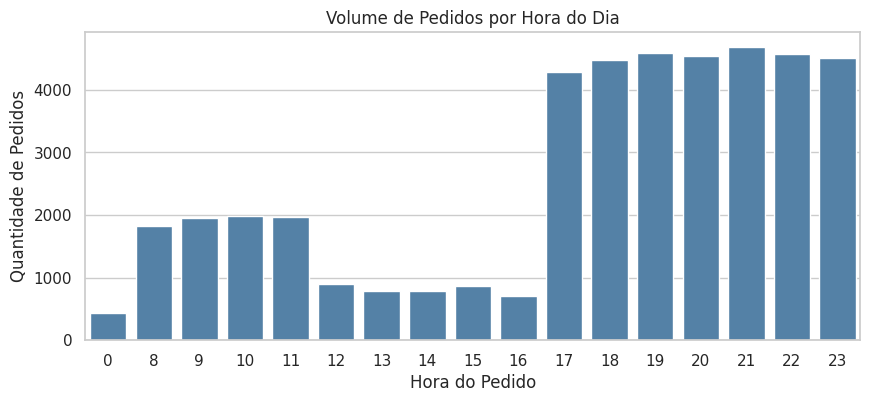


--- Tempo de entrega (min) por nível de trânsito ---
                      count   mean  median   std
Road_traffic_density                            
Low                   15062  21.28    20.0  6.80
Medium                10678  26.72    27.0  8.56
High                   4322  27.21    27.0  8.36
Jam                   13800  31.15    31.0  9.94


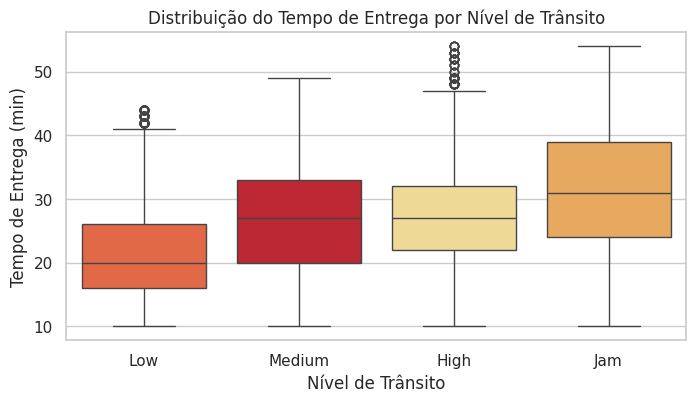

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# --- PERGUNTA 1: Horário de maior movimento ---
pedidos_por_hora = df_limpo['Hora_Pedido'].value_counts().sort_index()
print("--- Top 5 horários com mais pedidos ---")
print(df_limpo['Hora_Pedido'].value_counts().head(5))

plt.figure(figsize=(10, 4))
sns.barplot(x=pedidos_por_hora.index.astype(int), y=pedidos_por_hora.values, color='steelblue')
plt.title('Volume de Pedidos por Hora do Dia')
plt.xlabel('Hora do Pedido')
plt.ylabel('Quantidade de Pedidos')
plt.show()

# --- PERGUNTA 2: Trânsito vs Tempo de Entrega ---
ordem_transito = ['Low', 'Medium', 'High', 'Jam']
resumo_transito = df_limpo.groupby('Road_traffic_density')['Time_taken(min)'].agg(['count', 'mean', 'median', 'std']).reindex(ordem_transito)
print("\n--- Tempo de entrega (min) por nível de trânsito ---")
print(resumo_transito.round(2))

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=df_limpo,
    x='Road_traffic_density',
    y='Time_taken(min)',
    order=ordem_transito,
    hue='Road_traffic_density',
    palette='YlOrRd',
    legend=False
)
plt.title('Distribuição do Tempo de Entrega por Nível de Trânsito')
plt.xlabel('Nível de Trânsito')
plt.ylabel('Tempo de Entrega (min)')
plt.show()

## 6. Teste de Hipótese

Ensolarado (Sunny)  -> Quantidade: 7109 | Média: 21.85 min | Desvio padrão: 8.30
Tempestade (Stormy) -> Quantidade: 7402 | Média: 25.86 min | Desvio padrão: 8.46

Estatística t: 28.8295
Valor-p: 9.0245e-178
Resultado: Rejeitamos H0. A diferença entre os tempos de entrega é estatisticamente significativa!


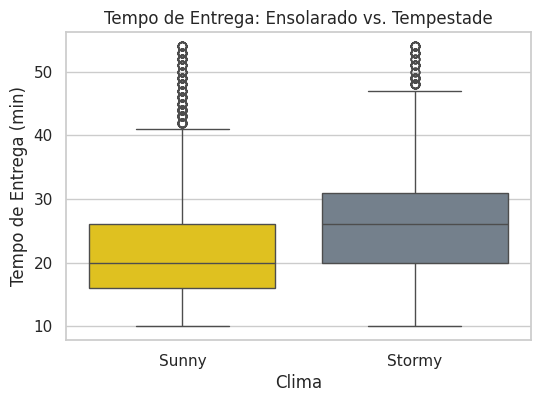

In [ ]:
from scipy import stats

# Separando os dois grupos
sunny = df_limpo[df_limpo['Weatherconditions'] == 'Sunny']['Time_taken(min)']
stormy = df_limpo[df_limpo['Weatherconditions'] == 'Stormy']['Time_taken(min)']

print(f"Ensolarado (Sunny)  -> Quantidade: {len(sunny)} | Média: {sunny.mean():.2f} min | Desvio padrão: {sunny.std():.2f}")
print(f"Tempestade (Stormy) -> Quantidade: {len(stormy)} | Média: {stormy.mean():.2f} min | Desvio padrão: {stormy.std():.2f}")

# Executando o Teste t de Welch
estatistica_t, valor_p = stats.ttest_ind(stormy, sunny, equal_var=False)

print(f"\nEstatística t: {estatistica_t:.4f}")
print(f"Valor-p: {valor_p:.4e}")

if valor_p < 0.05:
    print("Resultado: Rejeitamos H0. A diferença entre os tempos de entrega é estatisticamente significativa!")
else:
    print("Resultado: Não rejeitamos H0. Não há evidência de diferença significativa.")

# Gráfico comparando os dois grupos
df_clima = df_limpo[df_limpo['Weatherconditions'].isin(['Sunny', 'Stormy'])]
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_clima, x='Weatherconditions', y='Time_taken(min)', hue='Weatherconditions', palette=['gold', 'slategray'], legend=False)
plt.title('Tempo de Entrega: Ensolarado vs. Tempestade')
plt.xlabel('Clima')
plt.ylabel('Tempo de Entrega (min)')
plt.show()

## 7. Conclusões
- **Horários de pico:** O maior volume de pedidos se concentra no período noturno, entre **19h e 23h**, atingindo o pico às **21h** (4.686 pedidos).
- **Impacto do trânsito:** O trânsito é um fator crítico. Entregas em trânsito baixo (`Low`) levam em média **21,28 min** (desvio padrão de 6,80), enquanto em congestionamento (`Jam`) sobem para **31,15 min** (desvio padrão de 9,94) — quase 10 minutos a mais e com muito menos previsibilidade.
- **Clima (Teste de hipótese):** Aplicamos o **Teste t de Welch** comparando dias ensolarados (`Sunny`, média de 21,85 min) e dias de tempestade (`Stormy`, média de 25,86 min). O resultado foi uma estatística $t = 28,83$ e um **valor-p = $9,02 \times 10^{-178}$** ($p < 0,05$). Rejeita a hipótese nula ($H_0$), confirmando que a diferença de ~4 minutos é estatisticamente significativa.

## 8. Reflexão
- **Python vs. Planilhas:** Com mais de 45 mil linhas, planilhas comuns ficam lentas e difíceis de auditar. Em Python, limpar textos sujos em massa (`"NaN "`, `"(min) "`), gerar gráficos padronizados e rodar um teste de hipótese estatístico levou poucos segundos e pode ser reproduzido com um clique.